Визуализация и выводы

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

df = pd.read_csv('../data/raw_data/cookie_cats.csv')

gate_30 = df[df['version'] == 'gate_30']
gate_40 = df[df['version'] == 'gate_40']

# Метрики
n30, n40 = len(gate_30), len(gate_40)

conv_30_1 = gate_30['retention_1'].mean()
conv_40_1 = gate_40['retention_1'].mean()
conv_30_7 = gate_30['retention_7'].mean()
conv_40_7 = gate_40['retention_7'].mean()

# p-value
_, p_val_1 = proportions_ztest(
    [gate_30['retention_1'].sum(), gate_40['retention_1'].sum()],
    [n30, n40]
)
_, p_val_7 = proportions_ztest(
    [gate_30['retention_7'].sum(), gate_40['retention_7'].sum()],
    [n30, n40]
)

print("Данные готовы")
print(f"retention_1: {conv_30_1:.2%} vs {conv_40_1:.2%}, p = {p_val_1:.4f}")
print(f"retention_7: {conv_30_7:.2%} vs {conv_40_7:.2%}, p = {p_val_7:.4f}")

Данные готовы
retention_1: 44.82% vs 44.23%, p = 0.0744
retention_7: 19.02% vs 18.20%, p = 0.0016


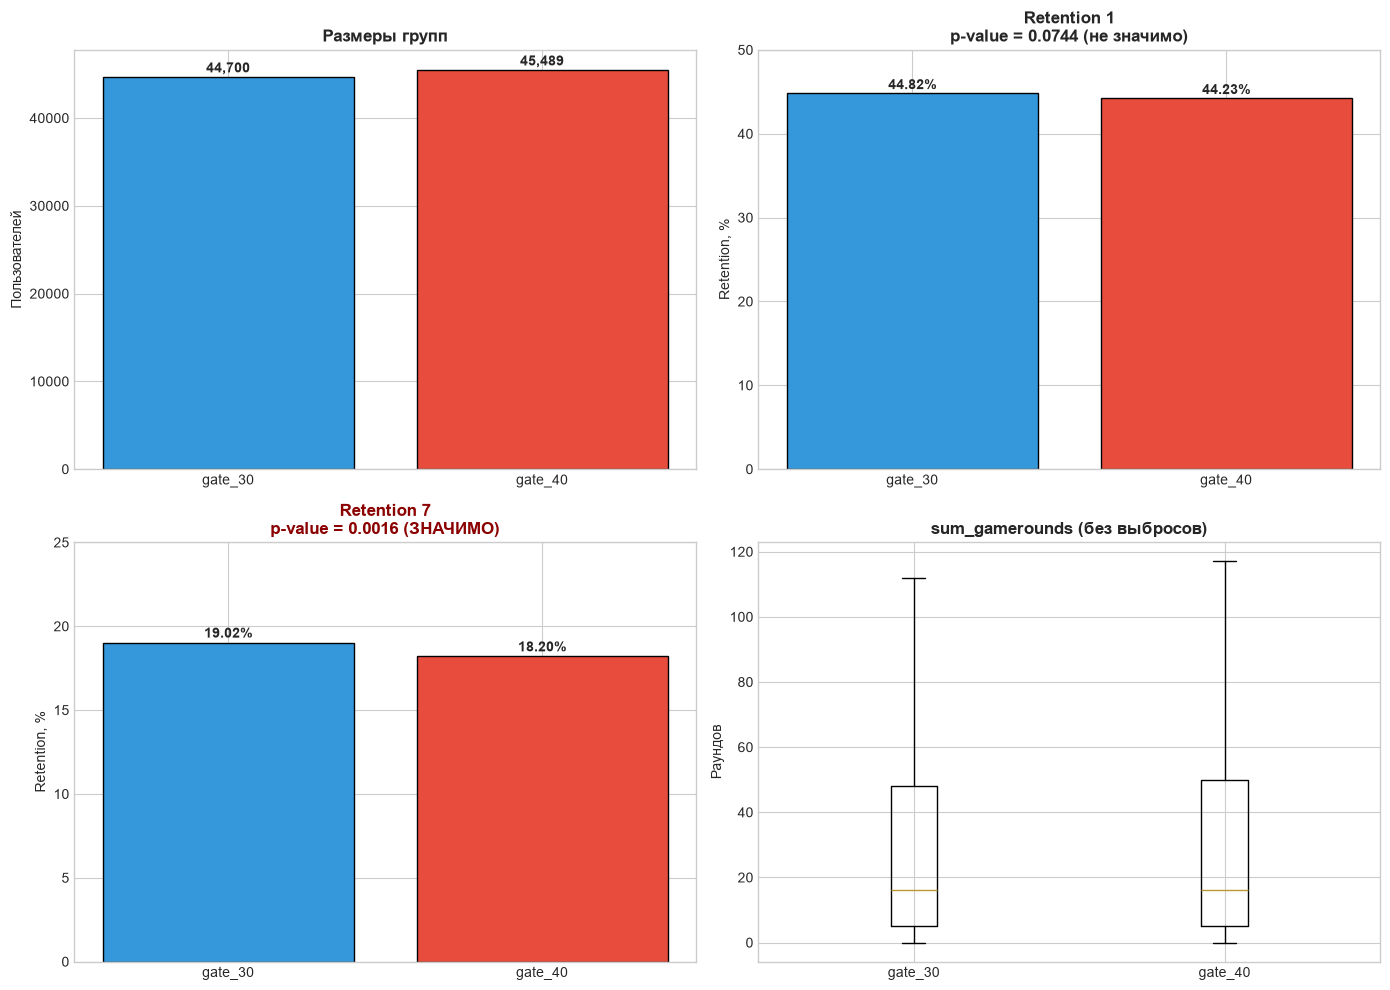

Сохранено: 06_final_dashboard.png


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# === 1. Размеры групп ===
groups = ['gate_30', 'gate_40']
sizes = [n30, n40]
colors = ['#3498db', '#e74c3c']

bars = axes[0, 0].bar(groups, sizes, color=colors, edgecolor='black')
axes[0, 0].set_title('Размеры групп', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Пользователей')
for bar, val in zip(bars, sizes):
    axes[0, 0].text(bar.get_x() + bar.get_width()/2, val + 500, f'{val:,}',
                    ha='center', fontweight='bold')

# === 2. Retention 1 ===
ret1 = [conv_30_1 * 100, conv_40_1 * 100]
bars = axes[0, 1].bar(groups, ret1, color=colors, edgecolor='black')
axes[0, 1].set_title(f'Retention 1\np-value = {p_val_1:.4f} (не значимо)', 
                     fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Retention, %')
axes[0, 1].set_ylim(0, 50)
for bar, val in zip(bars, ret1):
    axes[0, 1].text(bar.get_x() + bar.get_width()/2, val + 0.5, f'{val:.2f}%',
                    ha='center', fontweight='bold')

# === 3. Retention 7 ===
ret7 = [conv_30_7 * 100, conv_40_7 * 100]
bars = axes[1, 0].bar(groups, ret7, color=colors, edgecolor='black')
axes[1, 0].set_title(f'Retention 7\np-value = {p_val_7:.4f} (ЗНАЧИМО)', 
                     fontsize=12, fontweight='bold', color='darkred')
axes[1, 0].set_ylabel('Retention, %')
axes[1, 0].set_ylim(0, 25)
for bar, val in zip(bars, ret7):
    axes[1, 0].text(bar.get_x() + bar.get_width()/2, val + 0.3, f'{val:.2f}%',
                    ha='center', fontweight='bold')

# === 4. Распределение sum_gamerounds ===
# Ограничим по 99-му перцентилю
threshold = df['sum_gamerounds'].quantile(0.99)
data_30 = gate_30[gate_30['sum_gamerounds'] <= threshold]['sum_gamerounds']
data_40 = gate_40[gate_40['sum_gamerounds'] <= threshold]['sum_gamerounds']

axes[1, 1].boxplot([data_30, data_40], tick_labels=groups, showfliers=False)
axes[1, 1].set_title('sum_gamerounds (без выбросов)', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Раундов')

plt.tight_layout()
plt.savefig('../data/processed_data/06_final_dashboard.png', dpi=100, bbox_inches='tight')
plt.show()

print("Сохранено: 06_final_dashboard.png")

# Доверительные интервалы

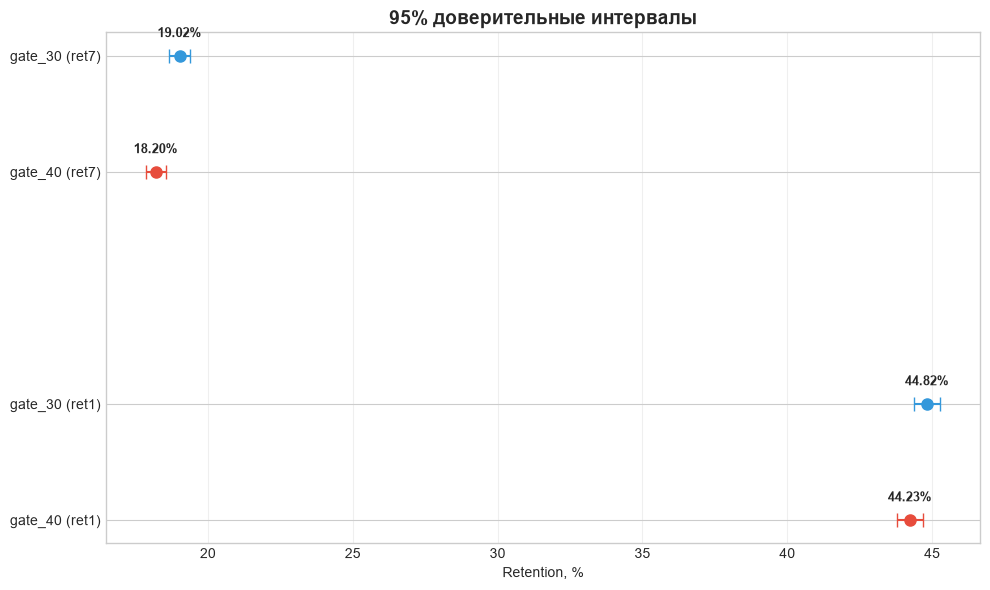

Сохранено: 06_confidence_intervals.png


In [6]:
fig, ax = plt.subplots(figsize=(10, 6))

# ДИ для retention_7
ci_30_7 = proportion_confint(gate_30['retention_7'].sum(), n30, method='wilson')
ci_40_7 = proportion_confint(gate_40['retention_7'].sum(), n40, method='wilson')

# ДИ для retention_1
ci_30_1 = proportion_confint(gate_30['retention_1'].sum(), n30, method='wilson')
ci_40_1 = proportion_confint(gate_40['retention_1'].sum(), n40, method='wilson')

# Позиции
y_pos = [2, 1.5, 0.5, 0]

# Точки
points = [conv_30_7, conv_40_7, conv_30_1, conv_40_1]
errors_low = [
    conv_30_7 - ci_30_7[0], conv_40_7 - ci_40_7[0],
    conv_30_1 - ci_30_1[0], conv_40_1 - ci_40_1[0]
]
errors_high = [
    ci_30_7[1] - conv_30_7, ci_40_7[1] - conv_40_7,
    ci_30_1[1] - conv_30_1, ci_40_1[1] - conv_40_1
]

colors = ['#3498db', '#e74c3c', '#3498db', '#e74c3c']
labels = ['gate_30 (ret7)', 'gate_40 (ret7)', 'gate_30 (ret1)', 'gate_40 (ret1)']

for i, (y, pt, el, eh, c, lbl) in enumerate(zip(y_pos, points, errors_low, errors_high, colors, labels)):
    ax.errorbar(pt * 100, y, xerr=[[el * 100], [eh * 100]], 
                fmt='o', color=c, capsize=5, markersize=8)
    ax.text(pt * 100, y + 0.08, f'{pt*100:.2f}%', ha='center', fontsize=9, fontweight='bold')

ax.set_yticks(y_pos)
ax.set_yticklabels(labels)
ax.set_xlabel('Retention, %')
ax.set_title('95% доверительные интервалы', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig('../data/processed_data/06_confidence_intervals.png', dpi=100, bbox_inches='tight')
plt.show()

print("Сохранено: 06_confidence_intervals.png")

# Распределение sum_gamerounds (визуализация скошенности)

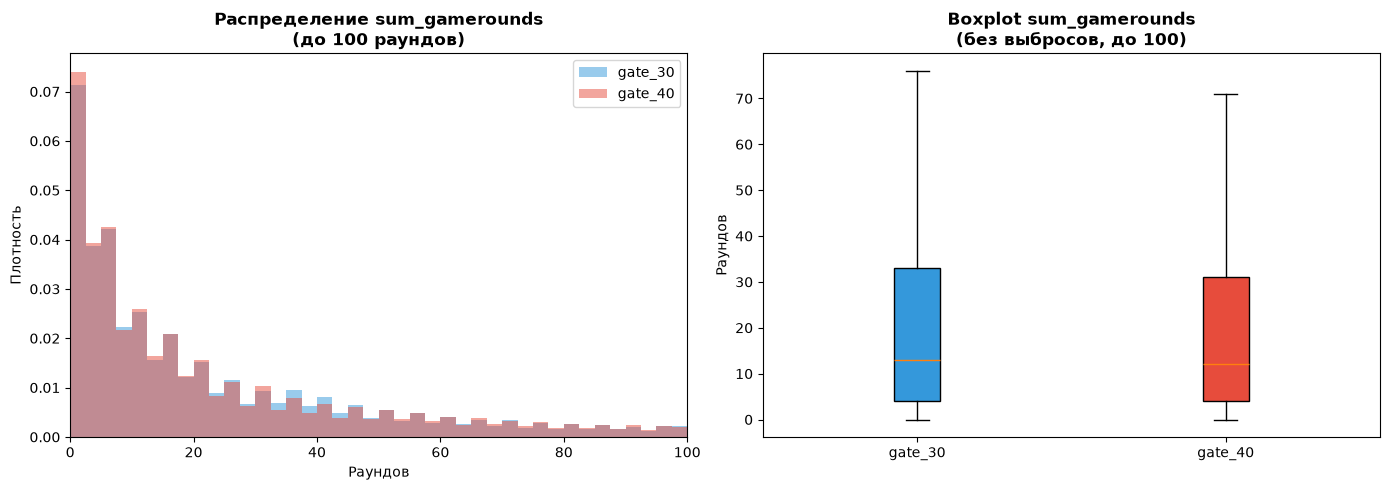

Сохранено: 09_distribution_bi.png


In [9]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../data/raw_data/cookie_cats.csv')

gate_30 = df[df['version'] == 'gate_30']
gate_40 = df[df['version'] == 'gate_40']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# === Левая: гистограмма до 100 ===
axes[0].hist(
    gate_30[gate_30['sum_gamerounds'] <= 100]['sum_gamerounds'],
    bins=40, alpha=0.5, label='gate_30', color='#3498db', density=True
)
axes[0].hist(
    gate_40[gate_40['sum_gamerounds'] <= 100]['sum_gamerounds'],
    bins=40, alpha=0.5, label='gate_40', color='#e74c3c', density=True
)
axes[0].set_title('Распределение sum_gamerounds\n(до 100 раундов)',
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('Раундов')
axes[0].set_ylabel('Плотность')
axes[0].legend()
axes[0].set_xlim(0, 100)

# === Правая: boxplot ===
data_30 = gate_30[gate_30['sum_gamerounds'] <= 100]['sum_gamerounds']
data_40 = gate_40[gate_40['sum_gamerounds'] <= 100]['sum_gamerounds']

bp = axes[1].boxplot(
    [data_30, data_40],
    tick_labels=['gate_30', 'gate_40'],
    showfliers=False,
    patch_artist=True
)
bp['boxes'][0].set_facecolor('#3498db')
bp['boxes'][1].set_facecolor('#e74c3c')
axes[1].set_title('Boxplot sum_gamerounds\n(без выбросов, до 100)',
                  fontsize=12, fontweight='bold')
axes[1].set_ylabel('Раундов')

plt.tight_layout()
plt.savefig('../data/processed_data/09_distribution_bi.png', dpi=150, bbox_inches='tight')
plt.show()

print("Сохранено: 09_distribution_bi.png")

# сводная таблица

In [9]:
# Сводная таблица
summary = pd.DataFrame({
    'Метрика': ['retention_1', 'retention_7', 'sum_gamerounds (медиана)'],
    'gate_30': [f'{conv_30_1:.2%}', f'{conv_30_7:.2%}', 
                f"{gate_30['sum_gamerounds'].median():.0f}"],
    'gate_40': [f'{conv_40_1:.2%}', f'{conv_40_7:.2%}', 
                f"{gate_40['sum_gamerounds'].median():.0f}"],
    'Разница': [
        f'{(conv_40_1 - conv_30_1):+.2%}',
        f'{(conv_40_7 - conv_30_7):+.2%}',
        f"{gate_40['sum_gamerounds'].median() - gate_30['sum_gamerounds'].median():+.0f}"
    ],
    'p-value': [f'{p_val_1:.4f}', f'{p_val_7:.4f}', '0.0502'],
    'Вердикт': ['НЕ значимо', 'ЗНАЧИМО', 'НЕ значимо']
})

print("=" * 80)
print("ФИНАЛЬНАЯ СВОДКА")
print("=" * 80)
print(summary.to_string(index=False))
print()

# Сохраняем таблицу в CSV
summary.to_csv('../data/processed_data/06_final_summary.csv', index=False)
print("Сохранено: 06_final_summary.csv")

ФИНАЛЬНАЯ СВОДКА
                 Метрика gate_30 gate_40 Разница p-value    Вердикт
             retention_1  44.82%  44.23%  -0.59%  0.0744 НЕ значимо
             retention_7  19.02%  18.20%  -0.82%  0.0016    ЗНАЧИМО
sum_gamerounds (медиана)      17      16      -1  0.0502 НЕ значимо

Сохранено: 06_final_summary.csv


In [ ]:
import pandas as pd
from sqlalchemy import create_engine

engine = create_engine(
    ""
)

# Выгружаем данные из MySQL
df = pd.read_sql("SELECT * FROM experiment_data", engine)
df.to_csv('../data/processed_data/experiment_data_for_bi.csv', index=False)
print("Сохранено:", len(df), "строк")

# Выгружаем сводку
summary = pd.read_csv('../data/processed_data/06_final_summary.csv')
summary.to_csv('../data/processed_data/summary_for_bi.csv', index=False)
print("Сводка сохранена")

Сохранено: 90189 строк
Сводка сохранена


# boxplot - 2 страница power bi

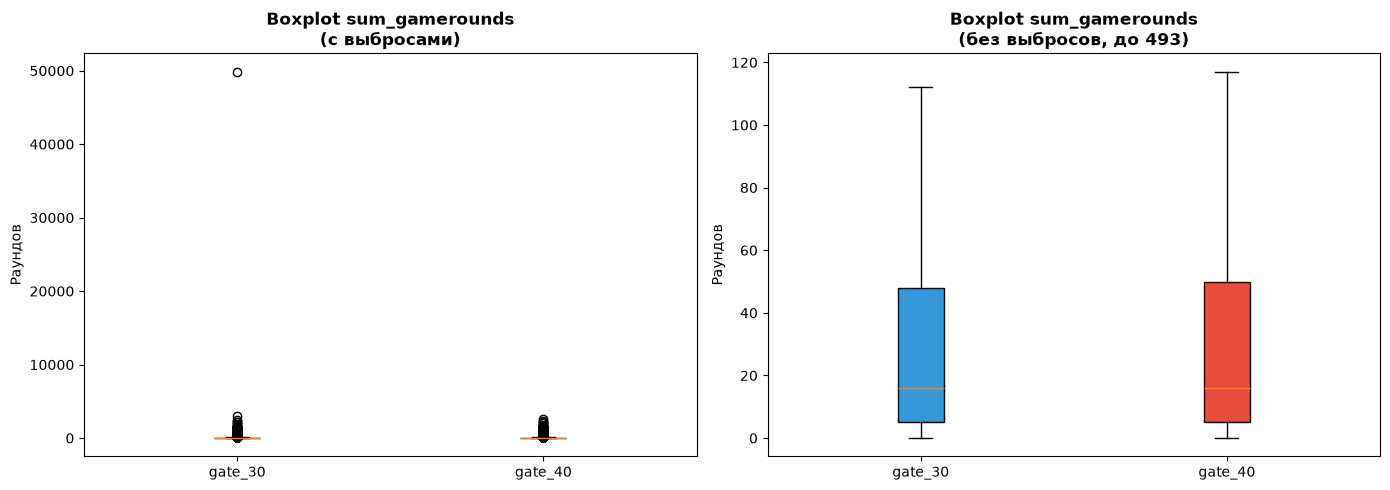

Сохранено: 09_boxplot_bi.png


In [6]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../data/raw_data/cookie_cats.csv')

gate_30 = df[df['version'] == 'gate_30']
gate_40 = df[df['version'] == 'gate_40']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# === Левая: boxplot с выбросами ===
bp = axes[0].boxplot(
    [gate_30['sum_gamerounds'], gate_40['sum_gamerounds']],
    tick_labels=['gate_30', 'gate_40'],
    showfliers=True,
    patch_artist=True
)
bp['boxes'][0].set_facecolor('#3498db')
bp['boxes'][1].set_facecolor('#e74c3c')
axes[0].set_title('Boxplot sum_gamerounds\n(с выбросами)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Раундов')

# === Правая: boxplot без выбросов (до 99-го перцентиля) ===
threshold = df['sum_gamerounds'].quantile(0.99)
data_30 = gate_30[gate_30['sum_gamerounds'] <= threshold]['sum_gamerounds']
data_40 = gate_40[gate_40['sum_gamerounds'] <= threshold]['sum_gamerounds']

bp = axes[1].boxplot(
    [data_30, data_40],
    tick_labels=['gate_30', 'gate_40'],
    showfliers=False,
    patch_artist=True
)
bp['boxes'][0].set_facecolor('#3498db')
bp['boxes'][1].set_facecolor('#e74c3c')
axes[1].set_title(f'Boxplot sum_gamerounds\n(без выбросов, до {threshold:.0f})', 
                  fontsize=12, fontweight='bold')
axes[1].set_ylabel('Раундов')

plt.tight_layout()
plt.savefig('../data/processed_data/09_boxplot_bi.png', dpi=150, bbox_inches='tight')
plt.show()

print("Сохранено: 09_boxplot_bi.png")

In [7]:
import os
path = '../data/processed_data/'
files = os.listdir(path)
for f in files:
    if f.startswith('09'):
        print(f, "—", os.path.getsize(os.path.join(path, f)), "байт")

09_boxplot_bi.png — 49663 байт
09_distribution_bi.png — 66091 байт


       Метрика gate_30 gate_40    Разница p-value          Вердикт
   Retention 1  44,82%  44,23% −0,59 п.п.  0,0744     ⚪ Не значимо
   Retention 7  19,02%  18,20% −0,82 п.п.  0,0016 🔴 Значимо (хуже)
sum_gamerounds      17      16   −1 раунд  0,0502     ⚪ Не значимо


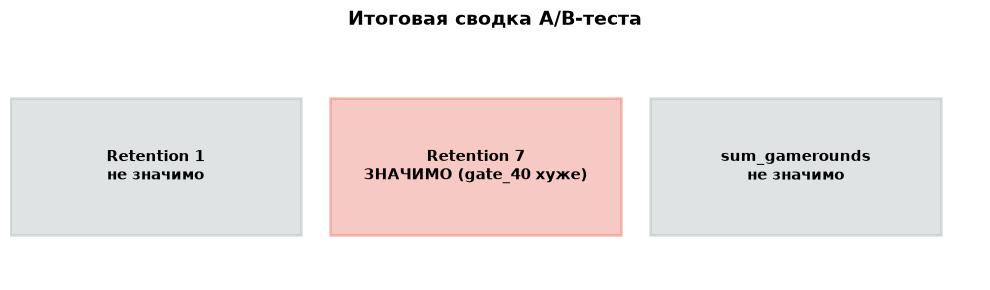

Сохранено: 06_verdict.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Сводка
summary = pd.DataFrame({
    'Метрика': ['Retention 1', 'Retention 7', 'sum_gamerounds'],
    'gate_30': ['44,82%', '19,02%', '17'],
    'gate_40': ['44,23%', '18,20%', '16'],
    'Разница': ['−0,59 п.п.', '−0,82 п.п.', '−1 раунд'],
    'p-value': ['0,0744', '0,0016', '0,0502'],
    'Вердикт': [' Не значимо', ' Значимо (хуже)', ' Не значимо']
})

print(summary.to_string(index=False))
summary.to_csv('../data/processed_data/08_final_conclusions.csv', index=False)

# Визуальная сводка
fig, ax = plt.subplots(figsize=(10, 3))
ax.axis('off')

colors = ['#95a5a6', '#e74c3c', '#95a5a6']
texts = [
    'Retention 1\nне значимо',
    'Retention 7\nЗНАЧИМО (gate_40 хуже)',
    'sum_gamerounds\nне значимо'
]

for i, (color, text) in enumerate(zip(colors, texts)):
    ax.add_patch(plt.Rectangle((i*0.33, 0.2), 0.3, 0.6, 
                                facecolor=color, alpha=0.3, 
                                edgecolor=color, linewidth=2))
    ax.text(i*0.33 + 0.15, 0.5, text, ha='center', va='center', 
            fontsize=11, fontweight='bold')

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title('Итоговая сводка A/B-теста', fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig('../data/processed_data/06_verdict.png', dpi=100, bbox_inches='tight')
plt.show()

print("Сохранено: 06_verdict.png")